## Дополнительное задание (ЛР1). Регрессия временных рядов

Цель: освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

Задание:
1) Загрузка и визуализация. Загрузить датасет, привести столбец с датой к типу datetime, отсортировать по времени. Построить график ряда. Сделать вывод: есть ли тренд, сезонность (суточная/недельная/годовая), выбросы.
2) Признаки. Сформировать признаки только из прошлого (без утечки данных из будущего):
* календарные: день недели, месяц, год, час (если есть), выходной/праздник;
* лаги: yt−1,…,yt−p​;
* скользящие статистики: скользящее среднее, медиана, стандартное отклонение, min/max за окно;
* сезонные признаки: значение ряда сутки/неделю/год назад (при наличии сезонности).
3) Разделение и кросс-валидация. Разделить ряд по времени (без перемешивания): train — ранние периоды, test — последние. Применить схему кросс-валидации для временных рядов (расширяющееся или скользящее окно).
4) Модель. Обучить регрессионную модель (линейная регрессия, Ridge/Lasso или градиентный бустинг) для прогноза на 1 шаг вперёд. Реализовать одну из стратегий прогноза на горизонт H шагов:
* рекурсивная — использовать собственные прогнозы как лаги;
* прямая — отдельная модель на каждый шаг;
* гибридная — комбинация.
5) Оценка качества. Рассчитать метрики: MSE, MAE, MAPE, WAPE. Сравнить качество на train и test. Проанализировать, где модель ошибается сильнее (тренд, сезонность, выбросы).
6) Декомпозиция. Выполнить STL-декомпозицию ряда, визуализировать тренд, сезонность и остаток. Проверить, улучшают ли признаки на основе компонент декомпозиции качество прогноза.

# Описание датасета
В работе используется датасет DailyDelhiClimate, содержащий ежедневные метеорологические наблюдения в Дели.

В качестве целевой переменной выбрана meantemp — средняя температура воздуха за день. 

Данные охватывают период с 1 января 2013 года по 24 апреля 2017 года и включают 1576 наблюдений.

# Импорты библиотек

In [31]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit

from statsmodels.tsa.seasonal import STL

# Загрузка и визуализация

Первые строки датасета:
             meantemp   humidity  wind_speed  meanpressure
date                                                      
2013-01-01  10.000000  84.500000    0.000000   1015.666667
2013-01-02   7.400000  92.000000    2.980000   1017.800000
2013-01-03   7.166667  87.000000    4.633333   1018.666667
2013-01-04   8.666667  71.333333    1.233333   1017.166667
2013-01-05   6.000000  86.833333    3.700000   1016.500000

Диапазон дат: 2013-01-01 — 2017-04-24
Количество наблюдений: 1576


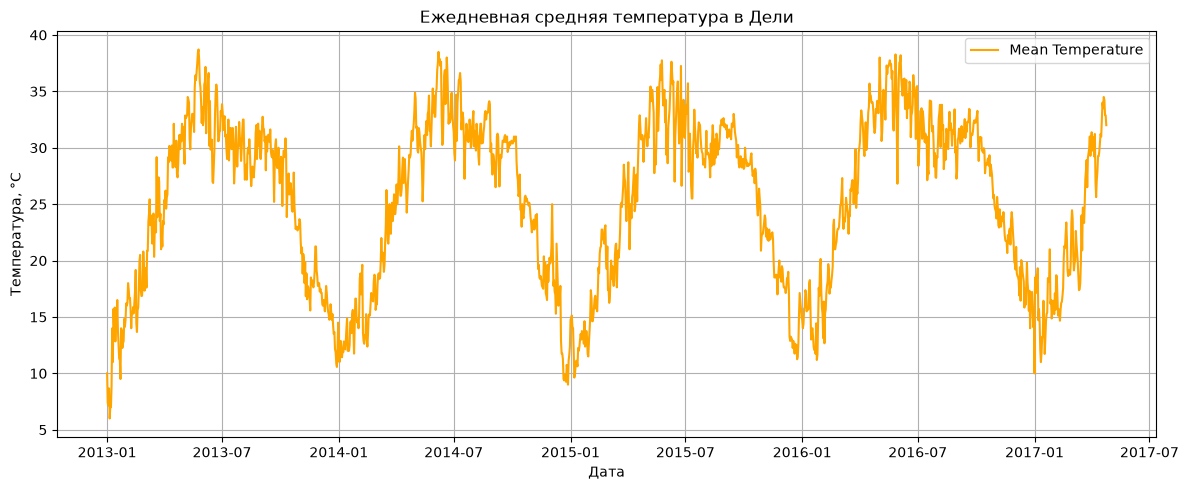

In [32]:
df = pd.read_csv('DailyDelhiClimate.csv')


df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)
df.set_index('date', inplace=True)

print('Первые строки датасета:')
print(df.head())
print(f'\nДиапазон дат: {df.index.min().date()} — {df.index.max().date()}')
print(f'Количество наблюдений: {len(df)}')

plt.figure(figsize=(12, 5))
plt.plot(df.index, df['meantemp'], label='Mean Temperature', color='orange')
plt.title('Ежедневная средняя температура в Дели')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Выводы
На графике средней дневной температуры наблюдаются выраженные периодические колебания. Температура повышается в тёплое время года и снижается в холодное. Например, в начале 2013 года значения находятся преимущественно в диапазоне примерно 6–15 °C, а летом температура достигает приблизительно 35–39 °C. Аналогичные циклы повторяются в последующие годы.

* Тренд. На представленном графике не наблюдается очевидного устойчивого долгосрочного роста или снижения температуры на протяжении всего рассматриваемого периода. При этом присутствуют регулярные подъёмы и спады, связанные с сезонными изменениями. Для более точного вывода о наличии тренда необходимо дополнительно исследовать сглаженный ряд или результат декомпозиции временного ряда.

* Сезонность. Наиболее заметна годовая сезонность: высокие температуры повторяются примерно в середине каждого года, а минимальные — в начале года. Повторяемость этих циклов указывает на зависимость температуры от времени года. Суточную сезонность по данному графику оценить нельзя, поскольку в датасете представлены ежедневные, а не почасовые наблюдения. Недельная сезонность также не прослеживается явно и требует дополнительной проверки, например с помощью анализа автокорреляции.

* Выбросы. На графике встречаются отдельные резкие изменения температуры относительно соседних дней. Однако сами по себе такие изменения не доказывают наличие статистических выбросов: они могут быть обусловлены реальными погодными условиями. Для выявления выбросов необходимо дополнительно использовать диаграмму размаха или межквартильный размах (IQR).

Исходный временной ряд не является случайной последовательностью независимых значений: в нём прослеживаются повторяющиеся годовые колебания и зависимость температуры от времени года. Поэтому при построении прогноза целесообразно использовать календарные признаки, значения температуры за предыдущие дни, скользящие статистики и методы, учитывающие временную структуру данных. Наличие тренда, недельной сезонности и статистических выбросов следует проверить дополнительными методами.

# Генерация признаков

Список признаков: ['dayofweek', 'month', 'year', 'day', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_30', 'lag_365', 'rolling_mean', 'rolling_std', 'rolling_min', 'rolling_max', 'rolling_median']
Количество признаков: 16
Количество строк после удаления пропусков: 1211
Период после формирования признаков: 2014-01-01 — 2017-04-24


,dayofweek,month,year,day,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_30,lag_365,rolling_mean,rolling_std,rolling_min,rolling_max,rolling_median,meantemp
date,,,,,,,,,,,,,,,,,
2014-01-01,2,1,2014,1,0,14.500,12.375,10.571429,13.666667,17.250000,10.000000,12.284014,1.410759,10.571429,14.5,12.125,13.375
2014-01-02,3,1,2014,2,0,13.375,14.500,12.375000,12.125000,17.500000,7.400000,12.242347,1.366737,10.571429,14.5,12.125,11.000
2014-01-03,4,1,2014,3,0,11.000,13.375,14.500000,11.875000,17.142857,7.166667,12.081633,1.446644,10.571429,14.5,11.875,12.500
2014-01-04,5,1,2014,4,1,12.500,11.000,13.375000,10.875000,17.142857,8.666667,12.170918,1.451046,10.571429,14.5,12.375,12.875
2014-01-05,6,1,2014,5,1,12.875,12.500,11.000000,10.571429,16.125000,6.000000,12.456633,1.346483,10.571429,14.5,12.500,12.375


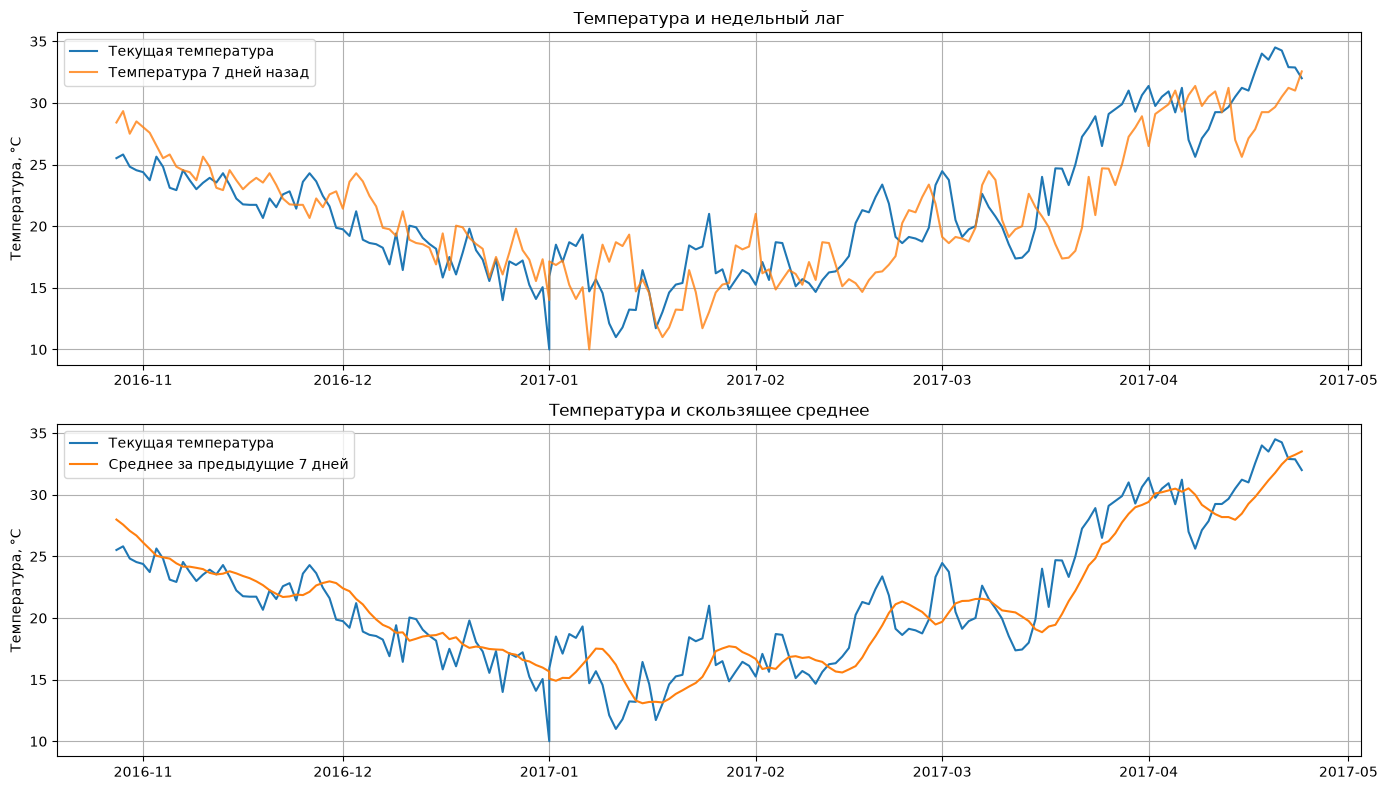

In [33]:

def create_features(data, target_col='meantemp', lags=3, window=7):
    df_feat = data.copy()

    df_feat['dayofweek'] = df_feat.index.dayofweek
    df_feat['month'] = df_feat.index.month
    df_feat['year'] = df_feat.index.year
    df_feat['day'] = df_feat.index.day
    df_feat['is_weekend'] = df_feat['dayofweek'].isin([5, 6]).astype(int)

    for i in range(1, lags + 1):
        df_feat[f'lag_{i}'] = df_feat[target_col].shift(i)

    for lag in [7, 30, 365]:
        df_feat[f'lag_{lag}'] = df_feat[target_col].shift(lag)

    shift_target = df_feat[target_col].shift(1)
    df_feat['rolling_mean'] = shift_target.rolling(window=window).mean()
    df_feat['rolling_std'] = shift_target.rolling(window=window).std()
    df_feat['rolling_min'] = shift_target.rolling(window=window).min()
    df_feat['rolling_max'] = shift_target.rolling(window=window).max()
    df_feat['rolling_median'] = shift_target.rolling(window=window).median()

    return df_feat


df_features = create_features(df, target_col='meantemp', lags=3, window=7)
df_features = df_features.dropna()

features = [
    c for c in df_features.columns
    if c not in ['meantemp', 'humidity', 'wind_speed', 'meanpressure']
]
target = 'meantemp'

print('Список признаков:', features)
print('Количество признаков:', len(features))
print('Количество строк после удаления пропусков:', len(df_features))
print('Период после формирования признаков:',
      df_features.index.min().date(), '—', df_features.index.max().date())

display(df_features[features + [target]].head())

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df_features.index[-180:], df_features['meantemp'].iloc[-180:],
             label='Текущая температура')
axes[0].plot(df_features.index[-180:], df_features['lag_7'].iloc[-180:],
             label='Температура 7 дней назад', alpha=0.8)
axes[0].set_title('Температура и недельный лаг')
axes[0].set_ylabel('Температура, °C')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(df_features.index[-180:], df_features['meantemp'].iloc[-180:],
             label='Текущая температура')
axes[1].plot(df_features.index[-180:], df_features['rolling_mean'].iloc[-180:],
             label='Среднее за предыдущие 7 дней')
axes[1].set_title('Температура и скользящее среднее')
axes[1].set_ylabel('Температура, °C')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Сформированы календарные признаки, лаги температуры за предыдущие 1–3, 7, 30 и 365 дней, а также скользящие статистики за последние 7 дней. Для исключения утечки данных скользящие статистики рассчитываются только по предыдущим наблюдениям. На графиках недельный лаг отражает температуру неделю назад, а скользящее среднее сглаживает краткосрочные колебания. Эти признаки позволяют модели учитывать недавнюю динамику температуры и повторяющиеся сезонные закономерности.

# Разделения

# Разделение строго по времени без перемешивания

In [34]:
test_size = int(len(df_features) * 0.2)
train_df = df_features.iloc[:-test_size].copy()
test_df  = df_features.iloc[-test_size:].copy()

X_train, y_train = train_df[features], train_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

print(f'\nРазмер Train: {len(X_train)}, Размер Test: {len(X_test)}')
print(f'Train: {X_train.index.min().date()} — {X_train.index.max().date()}')
print(f'Test:  {X_test.index.min().date()} — {X_test.index.max().date()}')


Размер Train: 969, Размер Test: 242
Train: 2014-01-01 — 2016-08-26
Test:  2016-08-27 — 2017-04-24


# Кросс-валидация временных рядов

КРОСС-ВАЛИДАЦИЯ (TimeSeriesSplit, расширяющееся окно)
Fold 1: train= 164, val=161 | MAE=1.544, RMSE=1.945
Fold 2: train= 325, val=161 | MAE=1.722, RMSE=2.151
Fold 3: train= 486, val=161 | MAE=1.332, RMSE=1.949
Fold 4: train= 647, val=161 | MAE=1.115, RMSE=1.522
Fold 5: train= 808, val=161 | MAE=1.560, RMSE=1.941

Средний MAE по CV: 1.455 ± 0.210
Средний RMSE по CV: 1.902 ± 0.206


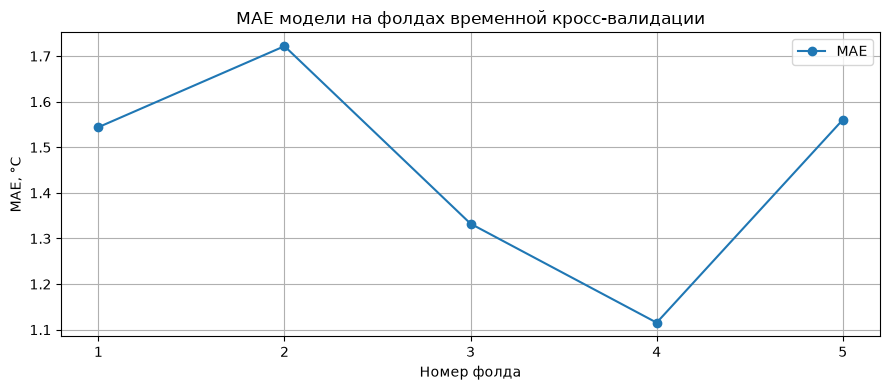

In [35]:
print('КРОСС-ВАЛИДАЦИЯ (TimeSeriesSplit, расширяющееся окно)')

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = []
cv_rmse_scores = []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

    model_cv = GradientBoostingRegressor(random_state=42)
    model_cv.fit(X_tr, y_tr)
    pred_val = model_cv.predict(X_val)

    mae = mean_absolute_error(y_val, pred_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred_val))

    cv_scores.append(mae)
    cv_rmse_scores.append(rmse)

    print(
        f'Fold {fold}: train={len(X_tr):4d}, val={len(X_val):3d} | '
        f'MAE={mae:.3f}, RMSE={rmse:.3f}'
    )

print(f'\nСредний MAE по CV: {np.mean(cv_scores):.3f} ± {np.std(cv_scores):.3f}')
print(f'Средний RMSE по CV: {np.mean(cv_rmse_scores):.3f} ± {np.std(cv_rmse_scores):.3f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(cv_scores) + 1), cv_scores, marker='o', label='MAE')
ax.set_title('MAE модели на фолдах временной кросс-валидации')
ax.set_xlabel('Номер фолда')
ax.set_ylabel('MAE, °C')
ax.set_xticks(range(1, len(cv_scores) + 1))
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()


Временная кросс-валидация показала средний MAE 1,455 °C и RMSE 1,902 °C. Наименьшая ошибка получена на четвёртом фолде (MAE = 1,115 °C), наибольшая — на втором (1,722 °C). Это указывает на то, что точность модели меняется в зависимости от временного периода. Полученные результаты можно использовать как базовый уровень для сравнения с итоговым качеством модели на тестовой выборке.

# Обучение модели

ОБУЧЕНИЕ МОДЕЛИ И ПРОГНОЗ

Метрики на обучающей выборке:
MAE: 0.901
MSE: 1.371
RMSE: 1.171
MAPE, %: 3.833
WAPE, %: 3.494

Метрики на тестовой выборке (прогноз на 1 день):
MAE: 1.181
MSE: 2.337
RMSE: 1.529
MAPE, %: 5.738
WAPE, %: 5.001


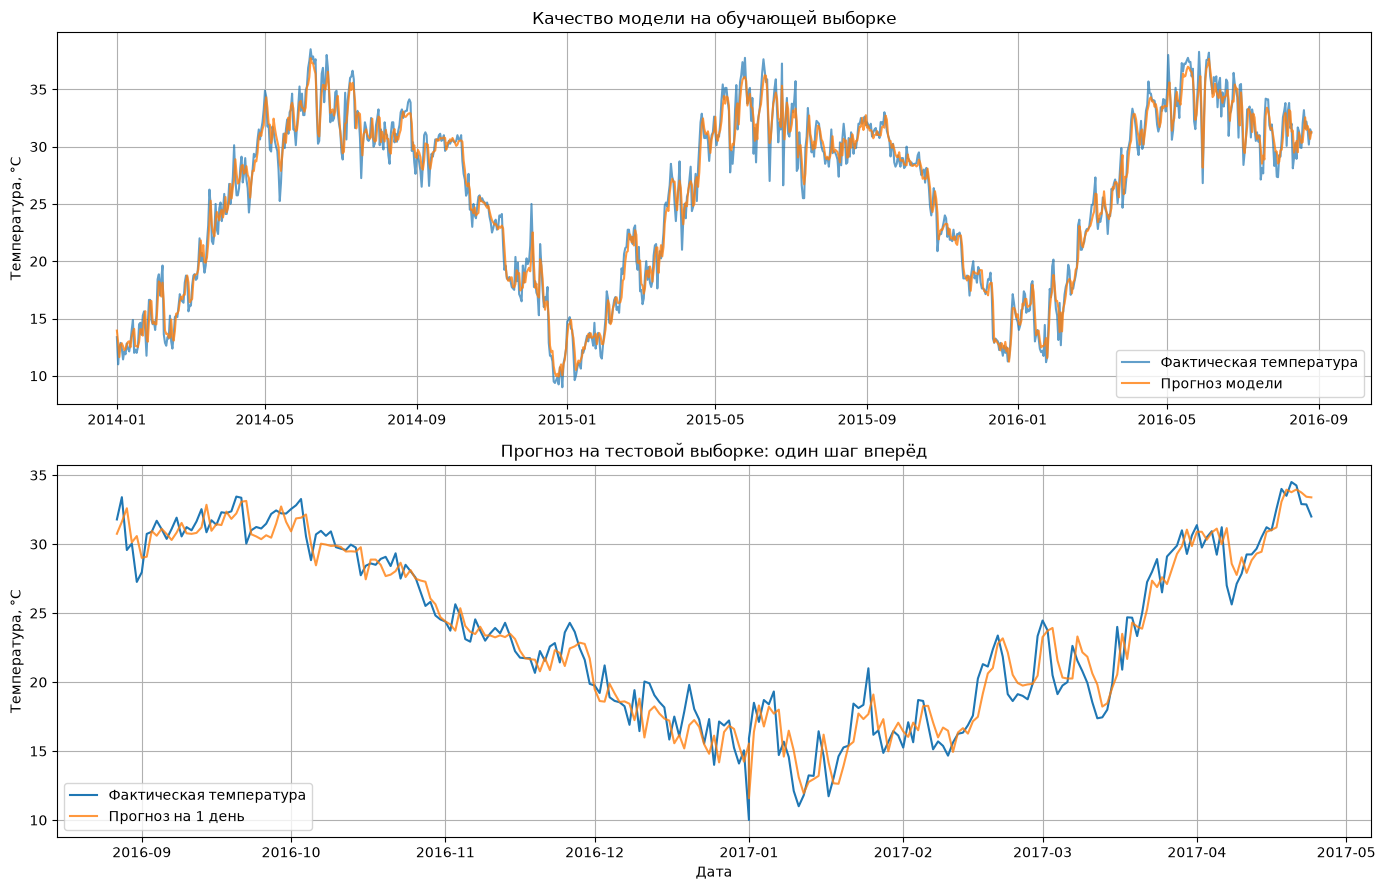

РЕКУРСИВНЫЙ ПРОГНОЗ НА ГОРИЗОНТ H
Горизонт прогноза H: 242 дней

Метрики рекурсивного прогноза:
MAE: 2.857
MSE: 13.011
RMSE: 3.607
MAPE, %: 13.936
WAPE, %: 12.096


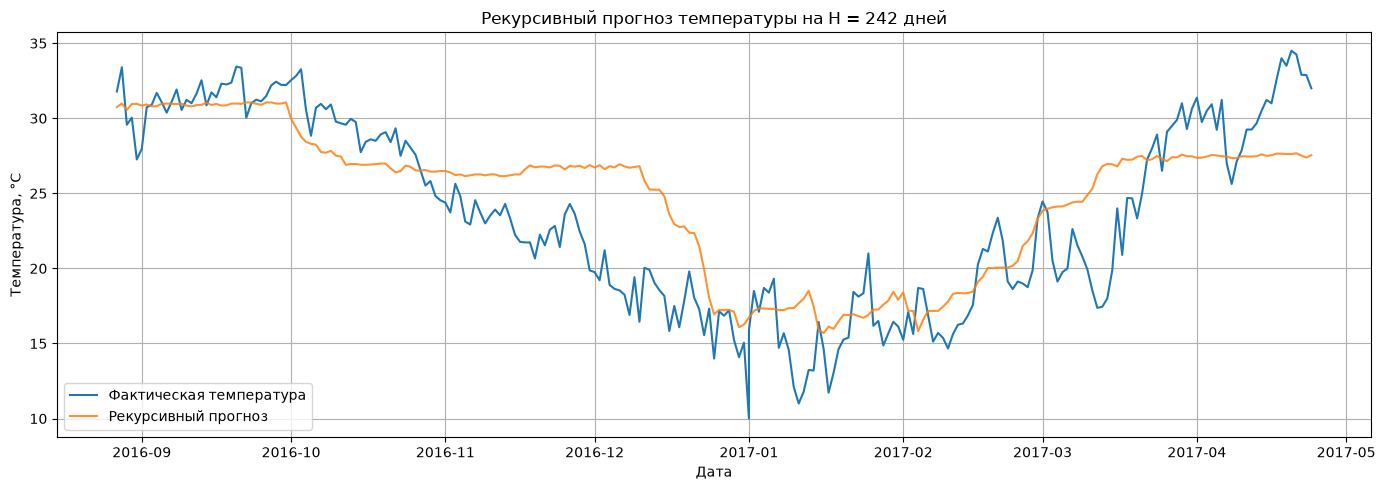

In [36]:
print('ОБУЧЕНИЕ МОДЕЛИ И ПРОГНОЗ')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)

    nonzero = np.abs(y_true) > 1e-8
    mape = (
        np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    wape = (
        np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100
        if np.sum(np.abs(y_true)) > 1e-8 else np.nan
    )

    return {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE, %': mape,
        'WAPE, %': wape
    }

train_metrics = calculate_metrics(y_train, y_pred_train)
test_metrics = calculate_metrics(y_test, y_pred_test)

print('\nМетрики на обучающей выборке:')
for name, value in train_metrics.items():
    print(f'{name}: {value:.3f}')

print('\nМетрики на тестовой выборке (прогноз на 1 день):')
for name, value in test_metrics.items():
    print(f'{name}: {value:.3f}')

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(y_train.index, y_train, label='Фактическая температура', alpha=0.7)
axes[0].plot(y_train.index, y_pred_train, label='Прогноз модели', alpha=0.8)
axes[0].set_title('Качество модели на обучающей выборке')
axes[0].set_ylabel('Температура, °C')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(y_test.index, y_test, label='Фактическая температура')
axes[1].plot(y_test.index, y_pred_test, label='Прогноз на 1 день', alpha=0.8)
axes[1].set_title('Прогноз на тестовой выборке: один шаг вперёд')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Температура, °C')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print('РЕКУРСИВНЫЙ ПРОГНОЗ НА ГОРИЗОНТ H')

H = len(test_df)
history = df.loc[:train_df.index[-1], target].copy()
recursive_predictions = []
recursive_dates = test_df.index

for date in recursive_dates:
    row = {}

    row['dayofweek'] = date.dayofweek
    row['month'] = date.month
    row['year'] = date.year
    row['day'] = date.day
    row['is_weekend'] = int(date.dayofweek in [5, 6])

    for lag in [1, 2, 3, 7, 30, 365]:
        lag_date = date - pd.Timedelta(days=lag)
        row[f'lag_{lag}'] = history.get(lag_date, np.nan)

    past_values = history.loc[history.index < date].tail(7)

    row['rolling_mean'] = past_values.mean()
    row['rolling_std'] = past_values.std()
    row['rolling_min'] = past_values.min()
    row['rolling_max'] = past_values.max()
    row['rolling_median'] = past_values.median()

    feature_row = pd.DataFrame([row], index=[date])
    feature_row = feature_row.reindex(columns=features)

    if feature_row.isna().any().any():
        raise ValueError(
            f'Не удалось сформировать все признаки для даты {date.date()}. '
            'Проверьте наличие истории для лагов.'
        )

    prediction = model.predict(feature_row)[0]
    recursive_predictions.append(prediction)

    history.loc[date] = prediction

y_pred_recursive = pd.Series(
    recursive_predictions,
    index=recursive_dates,
    name='recursive_prediction'
)

recursive_metrics = calculate_metrics(y_test, y_pred_recursive)

print(f'Горизонт прогноза H: {H} дней')
print('\nМетрики рекурсивного прогноза:')
for name, value in recursive_metrics.items():
    print(f'{name}: {value:.3f}')

plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test, label='Фактическая температура')
plt.plot(y_pred_recursive.index, y_pred_recursive,
         label='Рекурсивный прогноз', alpha=0.85)
plt.title(f'Рекурсивный прогноз температуры на H = {H} дней')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Выводы
1. Качество модели на обучающей и тестовой выборках
Для прогнозирования средней дневной температуры в Дели использована модель Gradient Boosting Regressor с 200 деревьями, скоростью обучения 0,05 и максимальной глубиной дерева 3.
На обучающей выборке получены MAE = 0,901 °C и RMSE = 1,171 °C. Это означает, что среднее абсолютное отклонение прогноза от фактической температуры составляет около 0,9 °C. На тестовой выборке MAE увеличивается до 1,181 °C, а RMSE — до 1,529 °C. Таким образом, на новых данных ошибка несколько выше, чем на обучающих, но остаётся сравнительно небольшой.
MAPE на тестовой выборке составляет 5,738%, а WAPE — 5,001%. Это означает, что относительная ошибка прогноза составляет примерно 5–6% по соответствующим способам расчёта. Разница между обучающими и тестовыми метриками указывает на некоторое снижение качества на новых данных, однако сама по себе не свидетельствует о сильном переобучении.

2. Анализ графиков одношагового прогноза
На графике обучающей выборки линии фактической температуры и прогноза модели в большинстве случаев расположены близко друг к другу. Модель хорошо воспроизводит основные сезонные изменения: рост температуры весной и снижение в холодный период. При этом отдельные резкие колебания воспроизводятся менее точно.
На тестовом графике прогноз также достаточно близко следует за фактическими значениями. Модель отражает общее снижение температуры с осени 2016 года к началу 2017 года и последующий рост весной. Однако в отдельных точках, например около резких скачков температуры в январе и марте 2017 года, заметны расхождения между линиями. Это показывает, что модель лучше улавливает общую динамику, чем внезапные изменения погоды.

3. Анализ рекурсивного прогноза
Для рекурсивного прогнозирования использован горизонт H = 242 дня. В отличие от одношагового прогноза, здесь каждое предсказанное значение добавляется в историю и используется для формирования признаков следующих дней. Поэтому ошибки предыдущих шагов могут накапливаться.
На тестовой выборке для одношагового прогноза MAE составляет 1,181 °C, а для рекурсивного — 2,857 °C. Ошибка рекурсивного прогноза примерно в 2,42 раза выше. RMSE увеличивается с 1,529 до 3,607 °C. MAPE возрастает с 5,738% до 13,936%, а WAPE — с 5,001% до 12,096%.
На графике рекурсивного прогноза видно, что предсказанная температура изменяется более плавно, чем фактическая. Особенно заметны расхождения в периоды резких колебаний и при переходе между сезонами. Например, в конце 2016 года и начале 2017 года модель не полностью воспроизводит кратковременные падения температуры. Весной 2017 года фактическая температура растёт быстрее, чем прогноз.
Такое поведение связано с особенностью рекурсивного подхода: модель использует собственные прогнозы вместо реальных наблюдений. Постепенно это снижает точность лаговых и скользящих признаков и приводит к накоплению ошибки.


Модель Gradient Boosting Regressor обеспечивает достаточно точный прогноз на один день вперёд: MAE на тестовой выборке составляет 1,181 °C. Однако при прогнозировании на 242 дня ошибка заметно увеличивается — до 2,857 °C. Графики подтверждают, что модель воспроизводит основные сезонные тенденции, но хуже справляется с резкими изменениями температуры и длительным прогнозированием. Следовательно, выбранный подход подходит для краткосрочного прогнозирования, тогда как для длинного горизонта необходимо дополнительно улучшать модель или проверять другие стратегии прогнозирования.

# Оценка качества


Метрики качества (прогноз на 1 шаг вперёд):
         MSE   RMSE    MAE  MAPE (%)  WAPE (%)
Model                                         
Train  1.371  1.171  0.901     3.833     3.494
Test   2.337  1.529  1.181     5.738     5.001


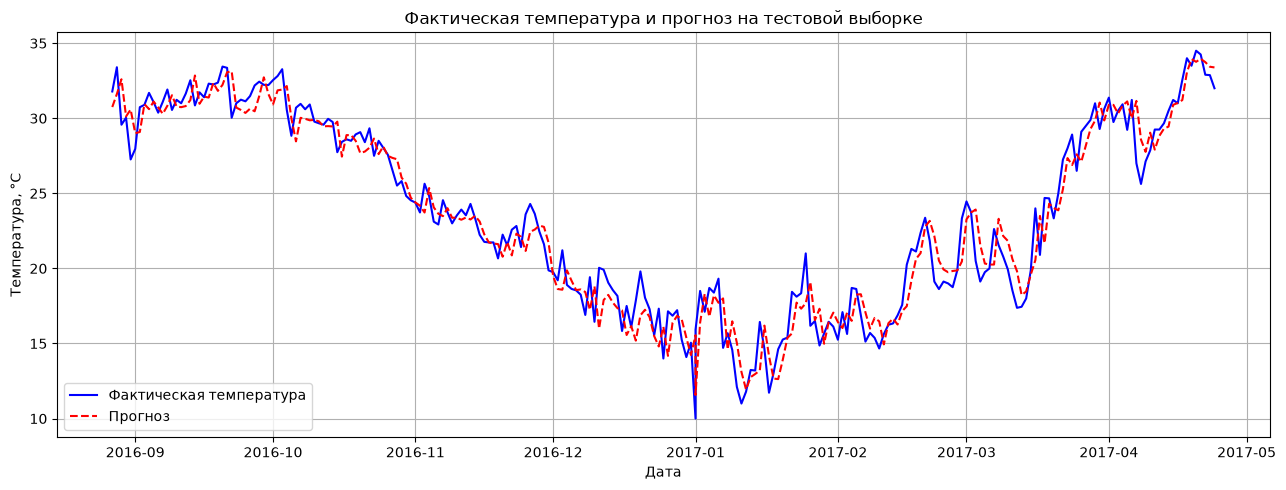

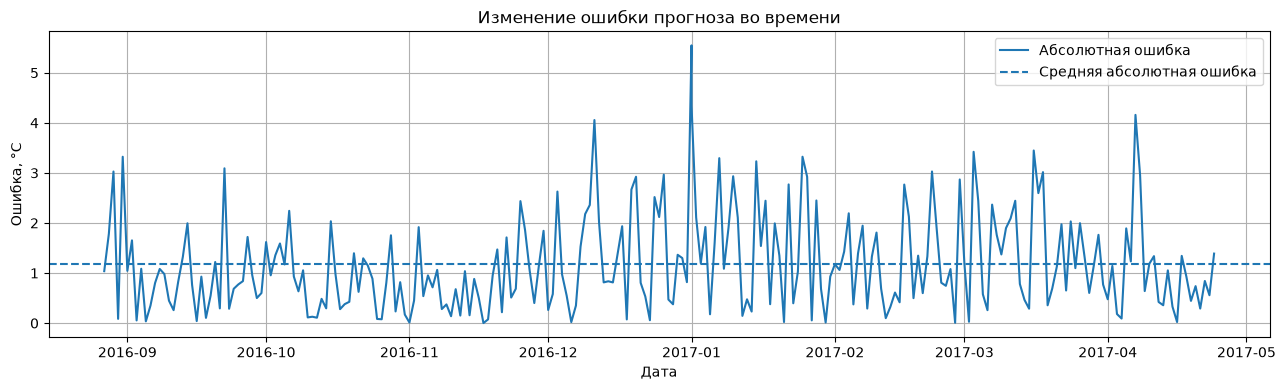

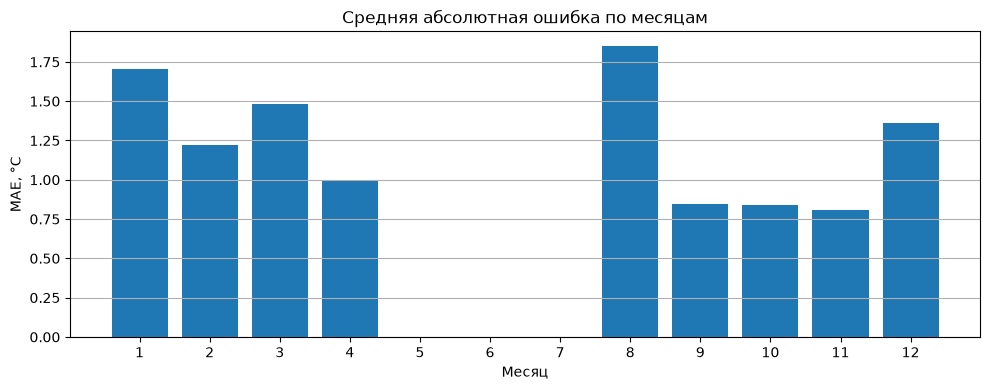


Месяц с наибольшей средней ошибкой: 8
Максимальная средняя ошибка по месяцу: 1.851 °C

Дни с наибольшими ошибками:
            Actual  Prediction  Absolute error  Month
date                                                 
2017-01-01  10.000      15.547           5.547      1
2017-01-01  15.913      11.574           4.339      1
2017-04-07  27.000      31.159           4.159      4
2016-12-11  20.042      15.986           4.056     12
2017-03-16  24.000      20.553           3.447      3
2017-03-03  20.500      23.921           3.421      3
2017-01-25  21.000      17.677           3.323      1
2016-08-31  27.259      30.582           3.323      8
2017-01-07  14.708      18.003           3.295      1
2017-01-15  16.435      13.204           3.231      1


In [37]:

def evaluate_metrics(y_true, y_pred, name=''):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)

    nonzero = np.abs(y_true) > 1e-9
    mape = (
        np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) /
                       y_true[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    total = np.sum(np.abs(y_true))
    wape = (
        np.sum(np.abs(y_true - y_pred)) / total * 100
        if total > 1e-9 else np.nan
    )

    return {
        'Model': name,
        'MSE': mse,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE (%)': mape,
        'WAPE (%)': wape
    }


metrics_train = evaluate_metrics(y_train, y_pred_train, 'Train')
metrics_test = evaluate_metrics(y_test, y_pred_test, 'Test')

metrics_df = pd.DataFrame(
    [metrics_train, metrics_test]
).set_index('Model')

print('\nМетрики качества (прогноз на 1 шаг вперёд):')
print(metrics_df.round(3))

errors = pd.DataFrame(index=y_test.index)
errors['Actual'] = y_test
errors['Prediction'] = y_pred_test
errors['Absolute error'] = np.abs(errors['Actual'] - errors['Prediction'])
errors['Month'] = errors.index.month

plt.figure(figsize=(13, 5))
plt.plot(errors.index, errors['Actual'],
         label='Фактическая температура', color='blue')
plt.plot(errors.index, errors['Prediction'],
         label='Прогноз', color='red', linestyle='--')
plt.title('Фактическая температура и прогноз на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 4))
plt.plot(errors.index, errors['Absolute error'],
         label='Абсолютная ошибка')
plt.axhline(errors['Absolute error'].mean(),
            linestyle='--', label='Средняя абсолютная ошибка')
plt.title('Изменение ошибки прогноза во времени')
plt.xlabel('Дата')
plt.ylabel('Ошибка, °C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

monthly_errors = errors.groupby('Month')['Absolute error'].mean()

plt.figure(figsize=(10, 4))
plt.bar(monthly_errors.index, monthly_errors.values)
plt.title('Средняя абсолютная ошибка по месяцам')
plt.xlabel('Месяц')
plt.ylabel('MAE, °C')
plt.xticks(range(1, 13))
plt.grid(axis='y')
plt.tight_layout()
plt.show()

print('\nМесяц с наибольшей средней ошибкой:',
      int(monthly_errors.idxmax()))
print('Максимальная средняя ошибка по месяцу:',
      round(monthly_errors.max(), 3), '°C')

print('\nДни с наибольшими ошибками:')
print(errors.nlargest(10, 'Absolute error').round(3))


# Анализ
На тестовой выборке модель показала MAE = 1,181 °C, RMSE = 1,529 °C, MAPE = 5,738% и WAPE = 5,001%. Это означает, что при прогнозировании температуры на один день вперёд среднее абсолютное отклонение от фактического значения составляет около 1,18 °C. Значение WAPE показывает, что суммарная абсолютная ошибка составляет около 5% от суммы абсолютных фактических температур.

На обучающей выборке MAE равна 0,901 °C, а на тестовой — 1,181 °C. Увеличение ошибки на тестовых данных ожидаемо: модель прогнозирует даты, которые не использовались при обучении. Разница не выглядит чрезмерной, поэтому результаты не указывают на сильное переобучение, хотя для окончательной оценки необходимо учитывать результаты временной кросс-валидации.

На первом графике видно, что прогноз в целом повторяет динамику фактической температуры: модель улавливает общее снижение температуры осенью и зимой, а затем её повышение весной. Однако при резких изменениях фактической температуры линии расходятся сильнее. Например, 1 января 2017 года фактическое значение составило 10 °C, а прогноз — 15,547 °C. Абсолютная ошибка в этот день равна 5,547 °C. Это показывает, что модель хуже предсказывает резкие скачки, чем плавные изменения.

На графике абсолютной ошибки заметны отдельные пики, превышающие 3–5 °C. При этом ошибка не остаётся постоянно высокой на протяжении всего тестового периода, а заметно колеблется от дня к дню. Это подтверждает, что точность прогноза зависит от конкретной ситуации и характера изменения температуры.

На графике средней ошибки по месяцам наибольшее значение наблюдается в августе — 1,851 °C. В сентябре–ноябре средняя ошибка ниже и составляет приблизительно 0,8–0,85 °C. Следовательно, на представленном тестовом периоде модель точнее прогнозировала температуру осенью, чем в августе. При этом тестовая выборка охватывает не полный календарный год, поэтому сравнение относится только к месяцам, представленным в тесте, и не доказывает, что август всегда является самым сложным месяцем для прогноза.

Таким образом, модель достаточно хорошо подходит для одношагового прогнозирования температуры: средняя абсолютная ошибка составляет около 1,18 °C, а общий сезонный ход температуры воспроизводится достаточно точно. Основное затруднение связано с резкими изменениями температуры, при которых ошибка может превышать 4–5 °C.

# Декомпозиция

STL-ДЕКОМПОЗИЦИЯ И СРАВНЕНИЕ МОДЕЛЕЙ


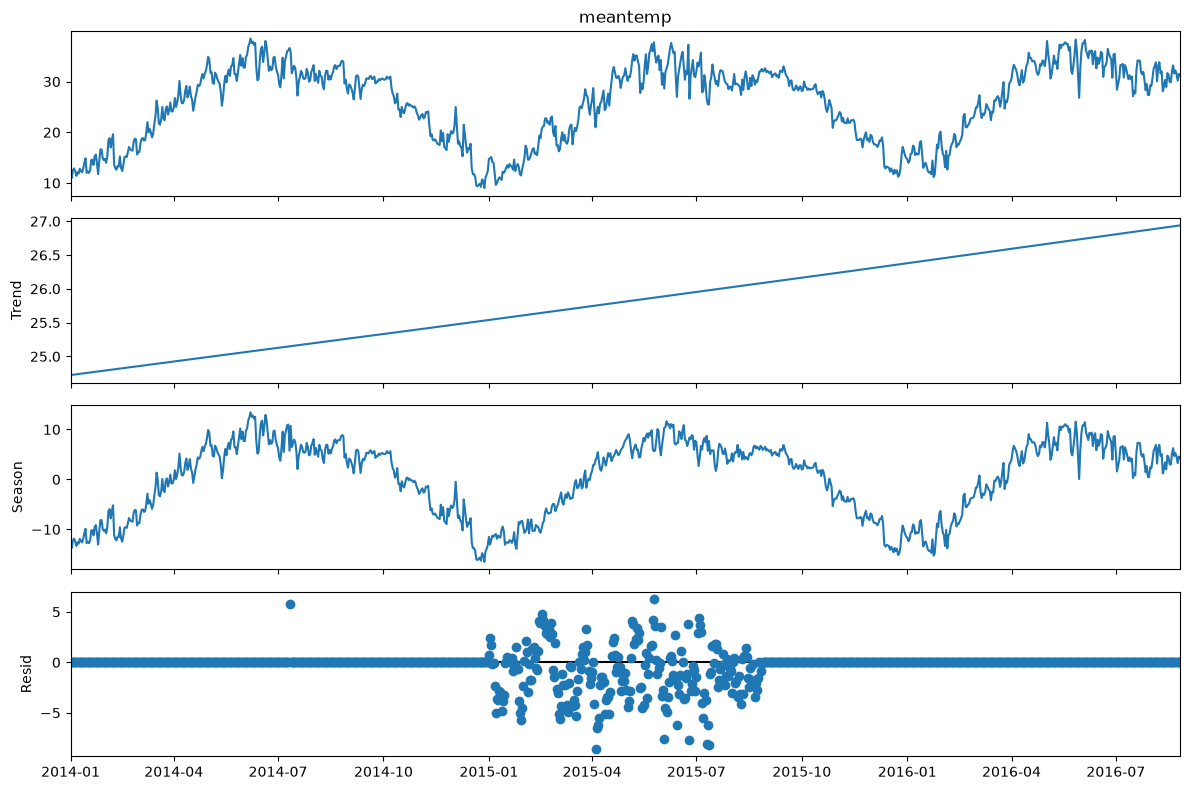

Среднее тренда: 25.818
Среднее сезонной компоненты: 0.227
Стандартное отклонение остатка: 1.459

Сравнение качества на тестовой выборке:
                           MSE   RMSE    MAE  MAPE (%)  WAPE (%)
Model                                                           
Исходная модель          2.337  1.529  1.181     5.738     5.001
Модель с STL-признаками  2.456  1.567  1.197     5.923     5.069


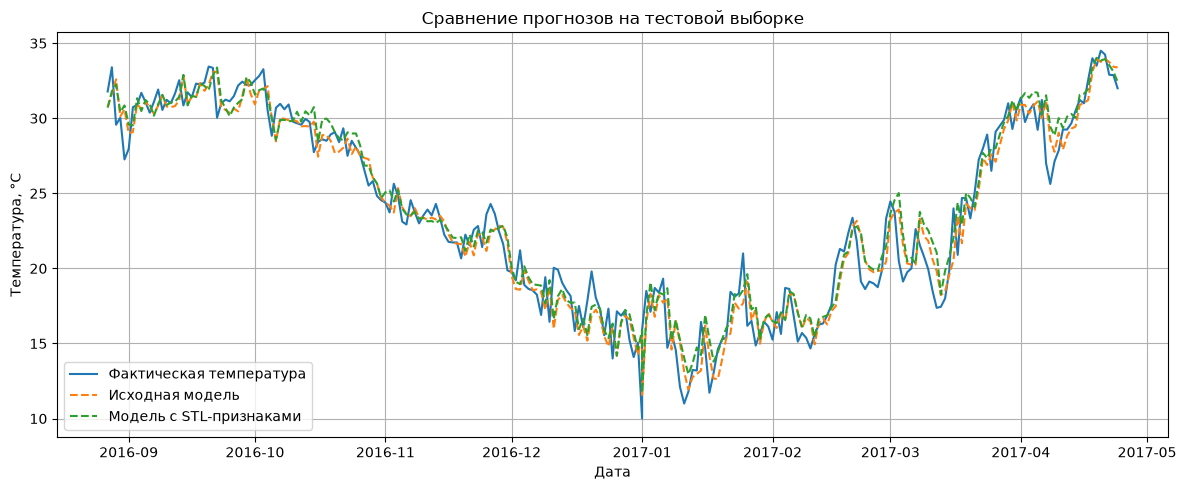


MAE исходной модели: 1.181 °C
MAE модели с STL: 1.197 °C
STL ухудшил MAE на 0.016 °C.


In [38]:

print('STL-ДЕКОМПОЗИЦИЯ И СРАВНЕНИЕ МОДЕЛЕЙ')

from statsmodels.tsa.seasonal import STL
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

stl = STL(train_df['meantemp'], period=365, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

trend_train = stl_result.trend
seasonal_train = stl_result.seasonal
resid_train = stl_result.resid

print('Среднее тренда:', round(trend_train.mean(), 3))
print('Среднее сезонной компоненты:', round(seasonal_train.mean(), 3))
print('Стандартное отклонение остатка:', round(resid_train.std(), 3))

X_train_stl = X_train.copy()
X_train_stl['stl_trend'] = trend_train.shift(1).reindex(X_train.index)
X_train_stl['stl_seasonal'] = seasonal_train.shift(1).reindex(X_train.index)

valid_rows = X_train_stl[['stl_trend', 'stl_seasonal']].notna().all(axis=1)
X_train_stl = X_train_stl.loc[valid_rows]
y_train_stl = y_train.loc[valid_rows]

X_test_stl = X_test.copy()

trend_model = np.polyfit(
    np.arange(len(trend_train)),
    trend_train.to_numpy(),
    deg=1
)

trend_future = np.polyval(
    trend_model,
    np.arange(len(trend_train), len(trend_train) + len(X_test_stl))
)

seasonal_values = seasonal_train.iloc[-365:].to_numpy()
seasonal_future = np.resize(seasonal_values, len(X_test_stl))

X_test_stl['stl_trend'] = trend_future
X_test_stl['stl_seasonal'] = seasonal_future

model_base = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
model_base.fit(X_train, y_train)
pred_base = model_base.predict(X_test)

model_stl = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
model_stl.fit(X_train_stl, y_train_stl)
pred_stl = model_stl.predict(X_test_stl)

comparison = pd.DataFrame([
    evaluate_metrics(y_test, pred_base, 'Исходная модель'),
    evaluate_metrics(y_test, pred_stl, 'Модель с STL-признаками')
]).set_index('Model')

print('\nСравнение качества на тестовой выборке:')
print(comparison.round(3))

plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label='Фактическая температура')
plt.plot(y_test.index, pred_base, '--', label='Исходная модель')
plt.plot(y_test.index, pred_stl, '--', label='Модель с STL-признаками')
plt.title('Сравнение прогнозов на тестовой выборке')
plt.xlabel('Дата')
plt.ylabel('Температура, °C')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

mae_base = mean_absolute_error(y_test, pred_base)
mae_stl = mean_absolute_error(y_test, pred_stl)

print(f'\nMAE исходной модели: {mae_base:.3f} °C')
print(f'MAE модели с STL: {mae_stl:.3f} °C')

change = mae_base - mae_stl
if change > 0:
    print(f'STL улучшил MAE на {change:.3f} °C.')
elif change < 0:
    print(f'STL ухудшил MAE на {-change:.3f} °C.')
else:
    print('MAE моделей совпадает.')


# Вывод
Для анализа временного ряда была выполнена STL-декомпозиция средней суточной температуры на трендовую, сезонную и остаточную компоненты. Среднее значение трендовой компоненты составило 25,818 °C, среднее значение сезонной компоненты — 0,227 °C, а стандартное отклонение остаточной компоненты — 1,459 °C.

Для проверки полезности компонент были сравнены две модели Gradient Boosting: исходная модель и модель с дополнительными STL-признаками. На тестовой выборке исходная модель показала MAE 1,181 °C и RMSE 1,529 °C. Для модели с STL-признаками значения составили 1,197 °C и 1,567 °C соответственно. Таким образом, добавление STL-признаков не привело к улучшению качества: MAE увеличилась на 0,016 °C, а RMSE — на 0,038 °C.

Полученные результаты показывают, что в данном эксперименте дополнительные STL-признаки не дали заметного преимущества перед исходными признаками модели. При этом небольшая разница в метриках не позволяет утверждать, что STL-признаки однозначно ухудшают прогноз во всех условиях. Для окончательного вывода потребовалась бы дополнительная проверка на нескольких временных разбиениях.

В проведённом эксперименте исходная модель Gradient Boosting показала немного более высокое качество прогнозирования. Добавление STL-признаков не повысило точность на тестовой выборке.

# Заключение
В ходе лабораторной работы была решена задача прогнозирования средней суточной температуры воздуха на основе временного ряда DailyDelhiClimate.csv. На этапе предварительной обработки данных были подготовлены временные признаки: день недели, месяц, год, день месяца и выходной день. Для учёта предыдущих значений температуры были сформированы лаговые признаки, а также скользящие статистики за последние семь дней.

Для построения прогноза использовалась модель Gradient Boosting Regressor с параметрами n_estimators=200, learning_rate=0.05 и  max_depth=3. Качество модели оценивалось с помощью MAE, MSE, RMSE, MAPE и WAPE. При проверке на тестовой выборке для прогноза на один шаг вперёд получены значения MAE = 1,181 °C и RMSE = 1,529 °C. Это означает, что средняя абсолютная ошибка прогноза составила около 1,18 °C.

Для оценки устойчивости модели также применялась кросс-валидация с последовательным разделением временного ряда. Средняя MAE по пяти разбиениям составила 1,455 °C, а средняя RMSE — 1,902 °C. Дополнительно был выполнен рекурсивный прогноз на 242 дня, соответствующих размеру тестовой выборки. При таком подходе MAE составила 2,857 °C, а RMSE — 3,607 °C. По сравнению с однодневным прогнозом точность снизилась, поскольку предсказанные значения последовательно использовались для формирования признаков следующих дней, что приводило к накоплению ошибок.

Также была проведена STL-декомпозиция временного ряда для анализа трендовой, сезонной и остаточной компонент. В эксперименте с добавлением STL-признаков MAE увеличилась с 1,181 до 1,197 °C, а RMSE — с 1,529 до 1,567 °C. Следовательно, в рамках проведённого сравнения дополнительные STL-признаки не улучшили качество модели. При интерпретации этого результата необходимо учитывать особенности формирования компонент и исключение утечки информации из будущего.

Полученные результаты показали, что модель Gradient Boosting обеспечивает более точный прогноз на один шаг вперёд, чем при длительном рекурсивном прогнозировании.